In [1]:
from pathlib import Path

from pywarper import layers

SACS = Path("../../skeliner/dev/SACs")
A17 = Path("../../skeliner/dev/data/mutilayers/AC/A17_large")

on  = layers.load_cells(SACS / "sac-on", "{id}/skeleton.npz")
off = layers.load_cells(SACS / "sac-off","{id}/skeleton.npz",)
a17 = layers.load_cells(A17, "{id}/skeleton.npz")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import skeliner as sk
from matplotlib.collections import LineCollection

from pywarper.surface import map_distortion
from pywarper.warpers import relative_depth, warp_skeleton

In [3]:
bands = layers.fit_bands(on, off)
on_soma = layers.soma_layer("on_soma", on, bands)
a17_layer = layers.stratum_layer("a17", a17, bands)
print(layers.report(bands, [on_soma, a17_layer]))

tissue 51.8% of the map; columns with both bands 30,809, ON only 4,697, OFF only 118
band gap 14.7 um (5-95% 12.8-16.8), 11.3-19.1 over the whole map
on: depth +0.00, 1,037 cells, observed over 99.8% of the tissue; 1,418 columns cut by a face, 683 too thin
off: depth +12.00, 686 cells, observed over 86.9% of the tissue; 1,039 columns cut by a face, 862 too thin
on_soma: depth -14.92, 1,037 cells, observed over 95.2% of the tissue; 971 somata used, 62 without room, 2 off the level; field -17.7 to -12.9 in the tissue
a17: depth -10.21, 263 cells, observed over 97.0% of the tissue; 208 columns cut by a face, 2,119 too thin; field -13.7 to -6.1 in the tissue


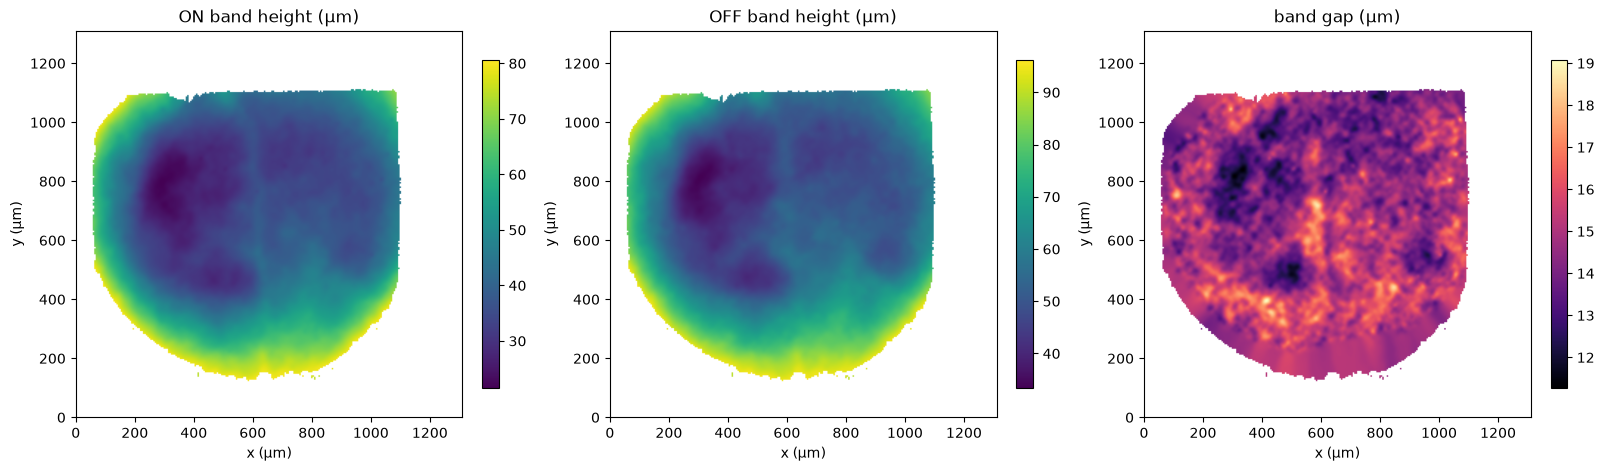

In [4]:
def tissue_only(field):
    return np.where(bands.tissue, field, np.nan).T


fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
panels = [
    (bands.on.height, "ON band height (µm)", "viridis"),
    (bands.off.height, "OFF band height (µm)", "viridis"),
    (bands.off.height - bands.on.height, "band gap (µm)", "magma"),
]
for ax, (field, title, cmap) in zip(axes, panels):
    image = ax.imshow(tissue_only(field), origin="lower", cmap=cmap)
    ax.set_title(title)
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")
    fig.colorbar(image, ax=ax, shrink=0.85)

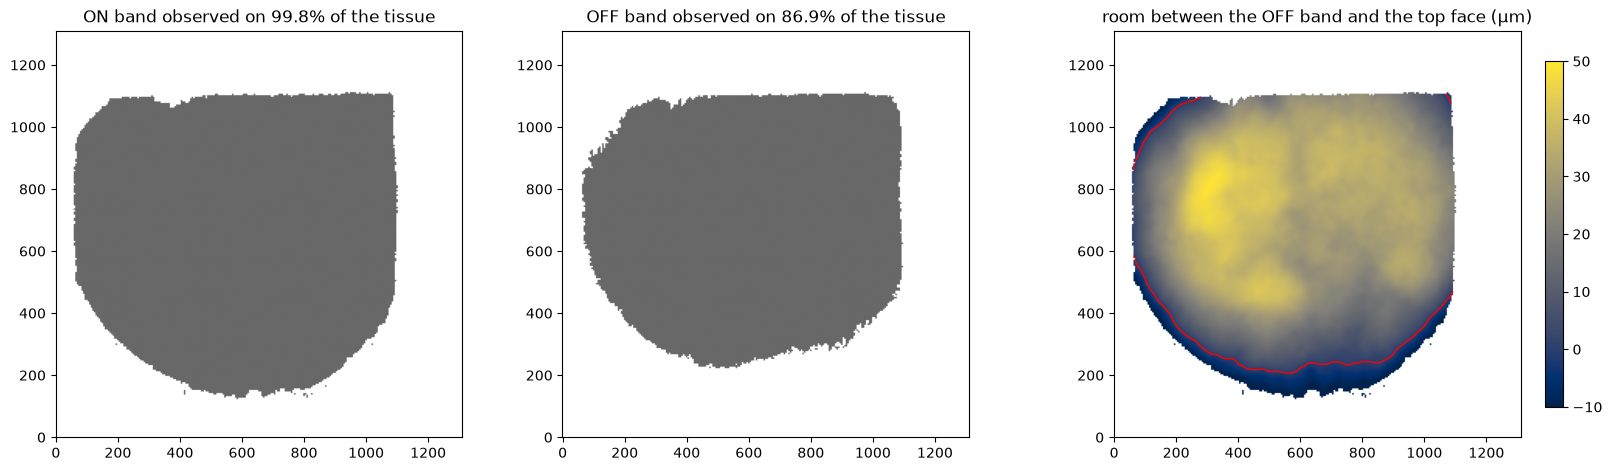

In [5]:
top = bands.volume_z[1]
room = tissue_only(top - bands.off.height)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), constrained_layout=True)
for ax, layer in zip(axes[:2], (bands.on, bands.off)):
    ax.imshow(tissue_only(layer.observed.astype(float)), origin="lower", cmap="Greys", vmin=0, vmax=1.5)
    ax.set_title(f"{layer.name.upper()} band observed on {layer.observed[bands.tissue].mean():.1%} of the tissue")
image = axes[2].imshow(room, origin="lower", cmap="cividis", vmin=-10, vmax=50)
axes[2].contour(room, levels=[0], colors="r", linewidths=1)
axes[2].set_title("room between the OFF band and the top face (µm)")
fig.colorbar(image, ax=axes[2], shrink=0.85)

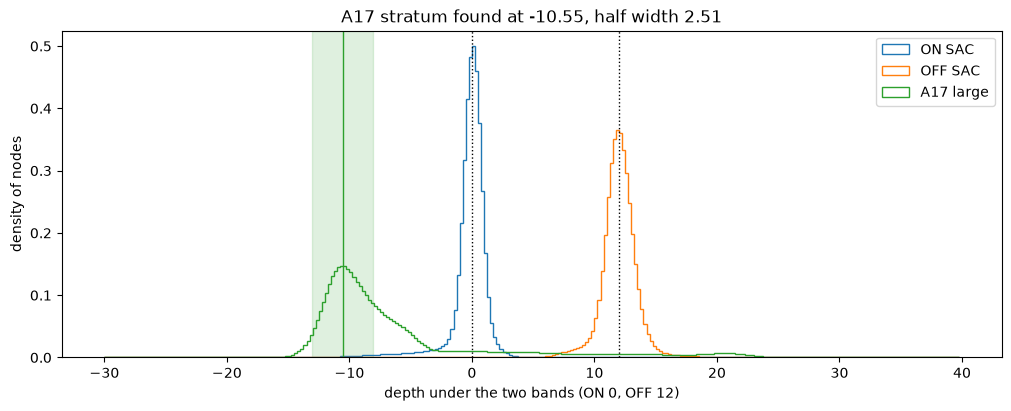

In [6]:
def two_band_depth(xyz):
    ix = np.clip(np.rint(xyz[:, 0]).astype(int), 0, bands.on.height.shape[0] - 1)
    iy = np.clip(np.rint(xyz[:, 1]).astype(int), 0, bands.on.height.shape[1] - 1)
    on_z, off_z = bands.on.height[ix, iy], bands.off.height[ix, iy]
    return 12 * (xyz[:, 2] - on_z) / (off_z - on_z)


peak = a17_layer.summary["profile_peak"]
half_width = a17_layer.summary["profile_half_width"]

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
bins = np.arange(-30, 40, 0.25)
for cells, label in ((on, "ON SAC"), (off, "OFF SAC"), (a17, "A17 large")):
    ax.hist(two_band_depth(cells.nodes), bins=bins, histtype="step", density=True, label=label)
ax.axvspan(peak - half_width, peak + half_width, color="C2", alpha=0.15)
ax.axvline(peak, color="C2", lw=1)
for depth in (0, 12):
    ax.axvline(depth, color="k", ls=":", lw=1)
ax.set_title(f"A17 stratum found at {peak:.2f}, half width {half_width:.2f}")
ax.set_xlabel("depth under the two bands (ON 0, OFF 12)")
ax.set_ylabel("density of nodes")
ax.legend()

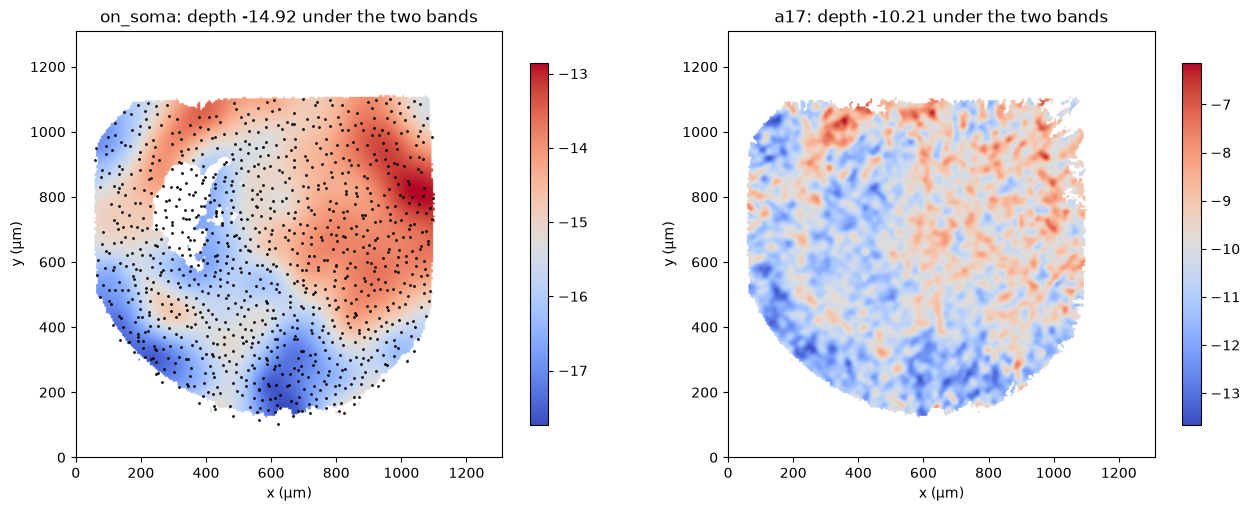

In [7]:
def layer_depth(layer):
    return 12 * (layer.height - bands.on.height) / (bands.off.height - bands.on.height)


somata = on.soma[np.isfinite(on.soma).all(axis=1)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, layer in zip(axes, (on_soma, a17_layer)):
    field = np.where(bands.tissue & layer.observed, layer_depth(layer), np.nan).T
    image = ax.imshow(field, origin="lower", cmap="coolwarm")
    ax.set_title(f"{layer.name}: depth {layer.depth:.2f} under the two bands")
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")
    fig.colorbar(image, ax=ax, shrink=0.85)
axes[0].scatter(somata[:, 0], somata[:, 1], s=1, c="k")

In [8]:
maps = {
    "two bands": layers.build_map(bands, [], conformal_jump=2),
    "+ ON soma layer": layers.build_map(bands, [on_soma], conformal_jump=2),
    "+ A17 layer": layers.build_map(bands, [on_soma, a17_layer], conformal_jump=2),
}

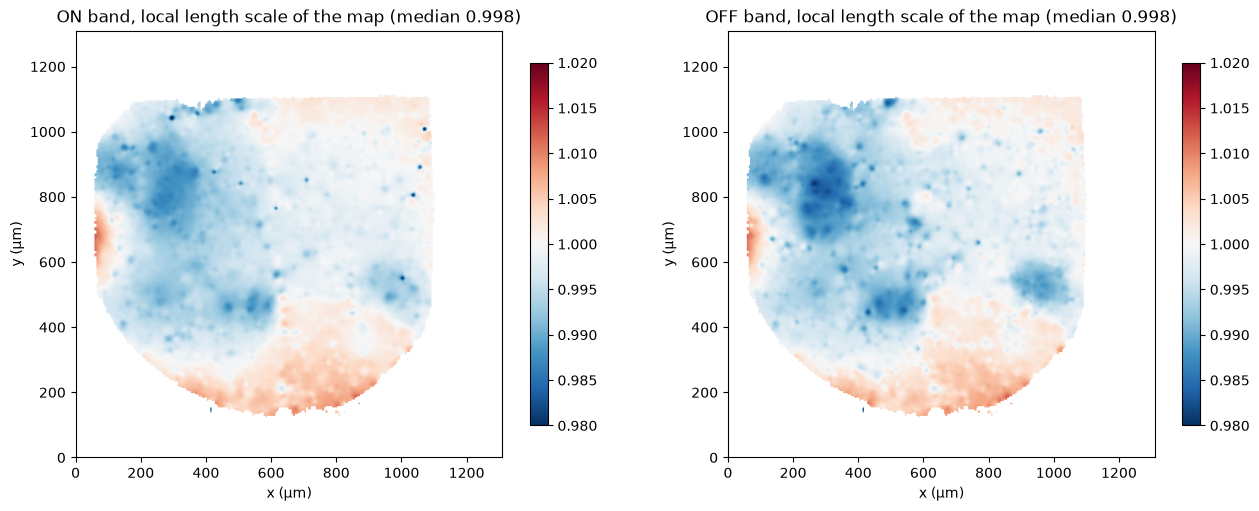

In [9]:
mapping = maps["two bands"]
sx, sy = mapping["sampled_x_idx"], mapping["sampled_y_idx"]
inside = bands.tissue[np.ix_(sx, sy)]
distortion = map_distortion(mapping, bands.tissue)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, band in zip(axes, ("on", "off")):
    scale = np.where(inside, distortion[band]["length_scale"], np.nan).T
    image = ax.imshow(scale, origin="lower", cmap="RdBu_r", vmin=0.98, vmax=1.02, extent=(sx[0], sx[-1], sy[0], sy[-1]))
    median = distortion[band]["summary"]["length_scale_median"]
    ax.set_title(f"{band.upper()} band, local length scale of the map (median {median:.3f})")
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")
    fig.colorbar(image, ax=ax, shrink=0.85)

Text(0, 0.5, 'depth of 540 held-out ON SAC somata')

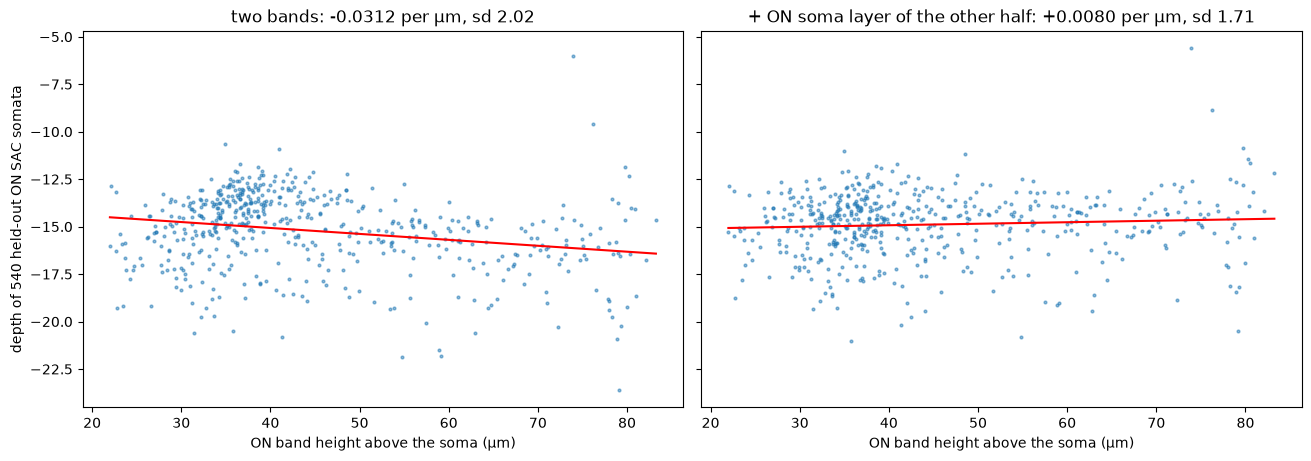

In [10]:
fitted = np.random.default_rng(0).random(len(on)) < 0.5
held_out = on.subset(~fitted)
xyz = held_out.soma[np.isfinite(held_out.soma).all(axis=1)]
two = 12 * relative_depth(xyz, maps["two bands"])
level = np.median(two)
xyz = xyz[np.abs(two - level) <= 5 * 1.4826 * np.median(np.abs(two - level))]
band_height = bands.on.height[np.rint(xyz[:, 0]).astype(int), np.rint(xyz[:, 1]).astype(int)]

held_out_maps = {
    "two bands": maps["two bands"],
    "+ ON soma layer of the other half": layers.build_map(
        bands, [layers.soma_layer("on_soma_half", on.subset(fitted), bands)], conformal_jump=2
    ),
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, constrained_layout=True)
for ax, (name, mapping) in zip(axes, held_out_maps.items()):
    depth = 12 * relative_depth(xyz, mapping)
    slope, intercept = np.polyfit(band_height, depth, 1)
    ax.scatter(band_height, depth, s=4, alpha=0.5)
    ends = np.array([band_height.min(), band_height.max()])
    ax.plot(ends, slope * ends + intercept, color="r")
    ax.set_title(f"{name}: {slope:+.4f} per µm, sd {depth.std():.2f}")
    ax.set_xlabel("ON band height above the soma (µm)")
axes[0].set_ylabel(f"depth of {len(xyz)} held-out ON SAC somata")

Text(0.5, 0, 'x (µm)')

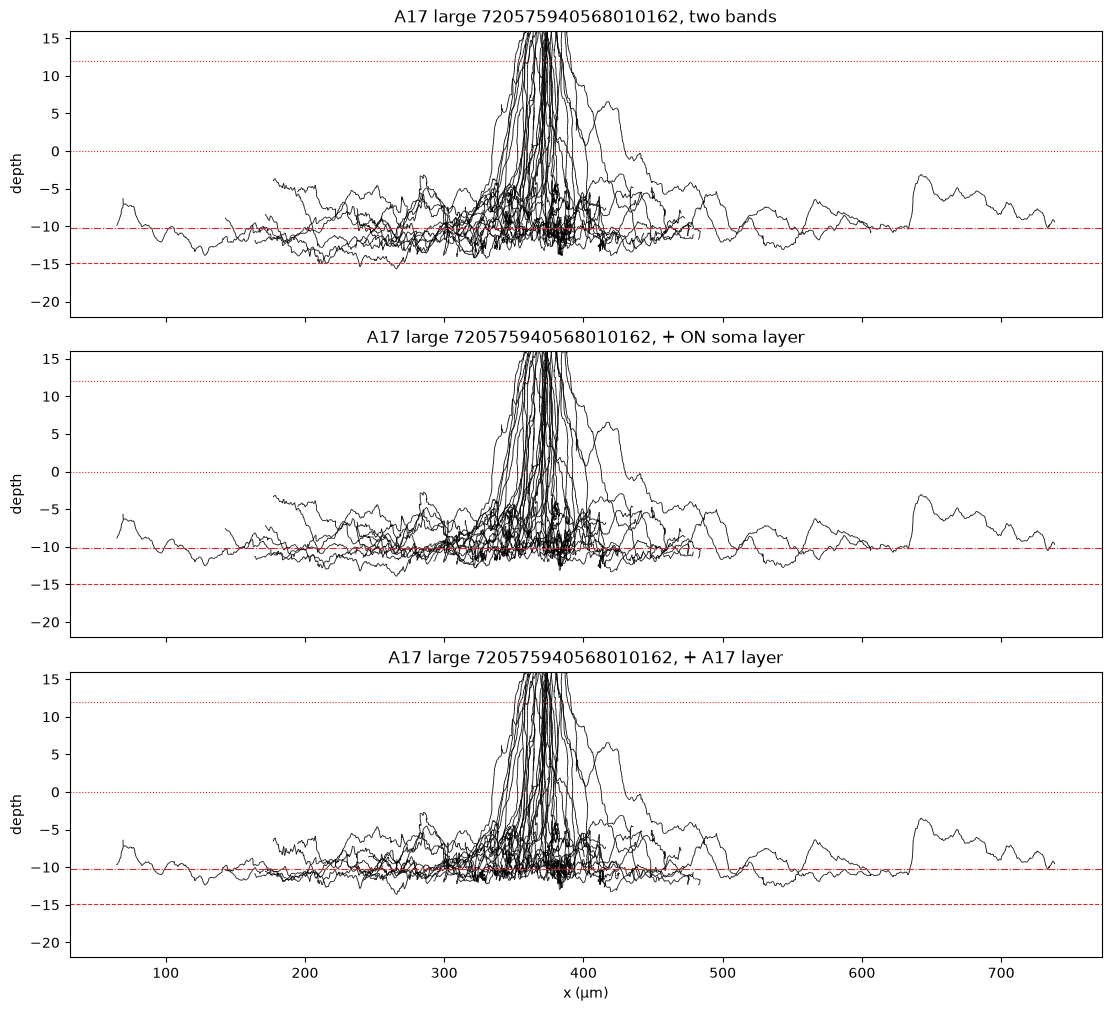

In [11]:
cell = "720575940568010162"
skel = sk.io.load_skeleton(A17 / cell / "skeleton.npz")
skel.convert_unit("um")

fig, axes = plt.subplots(len(maps), 1, figsize=(11, 10), sharex=True, constrained_layout=True)
for ax, (name, mapping) in zip(axes, maps.items()):
    nodes = np.asarray(warp_skeleton(skel, mapping).nodes)
    ax.add_collection(LineCollection(nodes[skel.edges][:, :, [0, 2]], colors="k", linewidths=0.6))
    for depth, style in ((0, ":"), (12, ":"), (on_soma.depth, "--"), (a17_layer.depth, "-.")):
        ax.axhline(depth, color="C3", ls=style, lw=0.8)
    ax.autoscale()
    ax.set_ylim(-22, 16)
    ax.set_title(f"A17 large {cell}, {name}")
    ax.set_ylabel("depth")
axes[-1].set_xlabel("x (µm)")

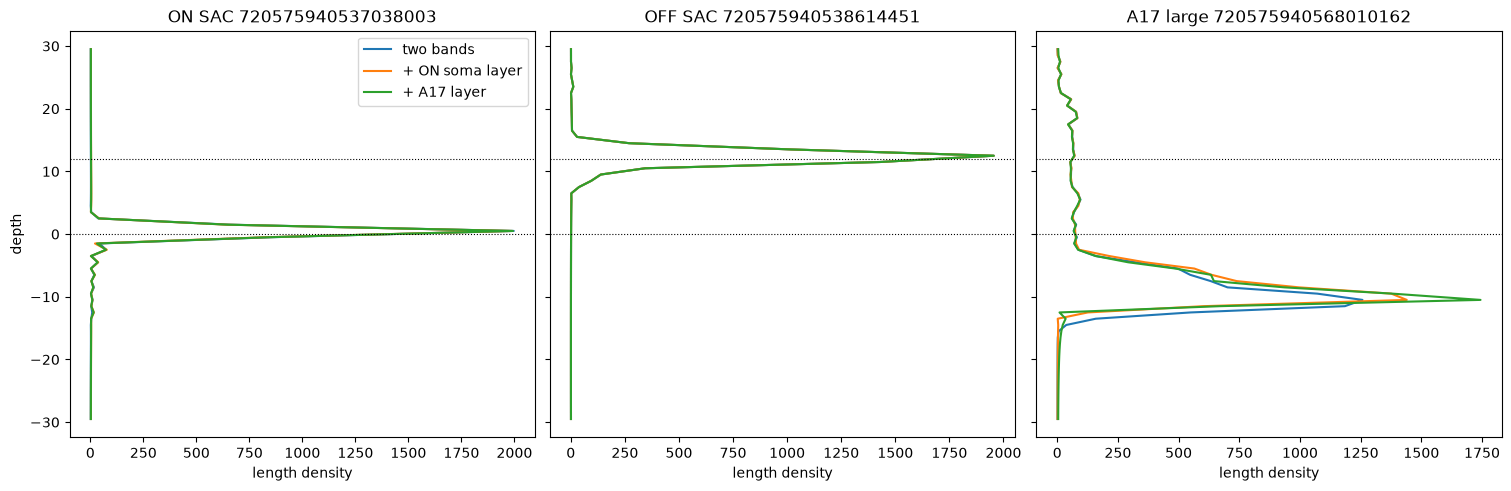

In [12]:
examples = {
    f"ON SAC {on.ids[0]}": SACS / "sac-on" / on.ids[0] / "skeleton.npz",
    f"OFF SAC {off.ids[0]}": SACS / "sac-off" / off.ids[0] / "skeleton.npz",
    f"A17 large {cell}": A17 / cell / "skeleton.npz",
}

fig, axes = plt.subplots(1, len(examples), figsize=(15, 4.8), sharey=True, constrained_layout=True)
for ax, (label, path) in zip(axes, examples.items()):
    example = sk.io.load_skeleton(path)
    example.convert_unit("um")
    for name, mapping in maps.items():
        profile = warp_skeleton(example, mapping, z_profile_extent=[-30, 30]).extra["z_profiles"]["length"]
        ax.plot(profile["distribution"], profile["x"], label=name)
    for depth in (0, 12):
        ax.axhline(depth, color="k", ls=":", lw=0.8)
    ax.set_title(label)
    ax.set_xlabel("length density")
axes[0].set_ylabel("depth")
axes[0].legend()

In [13]:
check = layers.check_cells(a17, a17_layer)
print(f"{check['off_layer'].sum()} of {len(a17)} A17 cells off the layer")
for seed in range(3):
    scores = layers.cross_validate("stratum", a17, bands, seed=seed)
    print(
        f"seed {seed}: held-out spread {scores['bands']['depth_sd']:.3f} with two bands, "
        f"{scores['layer']['depth_sd']:.3f} with the layer"
    )

2 of 263 A17 cells off the layer
seed 0: held-out spread 1.317 with two bands, 0.802 with the layer
seed 1: held-out spread 1.334 with two bands, 0.811 with the layer
seed 2: held-out spread 1.338 with two bands, 0.824 with the layer


In [14]:
%load_ext watermark
%watermark --time --date --timezone --updated --python --iversions --watermark

Last updated: 2026-11-20 16:44:50 CET

Python implementation: CPython
Python version       : 3.13.11
IPython version      : 9.18.1

matplotlib: 3.11.2
numpy     : 2.5.5
pywarper  : 0.3.0
skeliner  : 0.4.1

Watermark: 2.6.0

